# Systemy operacyjne - Laboratorium 3

In [181]:
import random
from typing import List
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

### Parametry symulacji

In [182]:
PHYSICAL_FRAMES_COUNT = 18
VIRTUAL_PAGES_COUNT = 100
REFERENCE_SEQUENCE_LENGTH = 1000
# RANDOM_SEED = 35

LOCALITY_PROBABILITY = 0.9
SPATIAL_LOCALITY_PROBABILITY = 0.25
AVERAGE_REFERENCES_PER_SET = 50
AVERAGE_SET_SIZE = 20

FRAMES_SIMULATION_SEQ = [3, 5, 10, 12, 15, 22, 30, 40, 52]

### Generowanie ciągu odwołań (z uwzględnieniem lokalności)

In [183]:
# random.seed(RANDOM_SEED)

def generate_reference_sequence(
        sequence_length: int,
        locality_probability: float,
        spatial_locality_probability: float,
        average_references_per_set: int,
        average_set_size: int
) -> List[int]:
    seq = []
    pages = set(range(VIRTUAL_PAGES_COUNT * 2))
    working_set = set(random.sample(list(pages), average_set_size))
    counter = 0

    while len(seq) < sequence_length:
        if random.random() < locality_probability and working_set:
            page = random.choice(list(working_set))
            
            if random.random() < spatial_locality_probability:
                for next_to in [page-1, page+1]:
                    if 0 <= next_to < sequence_length:
                        working_set.add(next_to)
        else:
            available = list(pages - working_set)
            page = random.choice(available) if available else 0
            
        seq.append(page)
        counter += 1
        
        if counter >= average_references_per_set:
            working_set = set(random.sample(list(pages - working_set), average_set_size))
            counter = 0

    return seq


# print(generate_reference_sequence(REFERENCE_SEQUENCE_LENGTH ,PHYSICAL_FRAMES_COUNT, LOCALITY_PROBABILITY, AVERAGE_REFERENCES_PER_SET, AVERAGE_SET_SIZE))

### Algorytm FIFO

In [184]:
def fifo(reference_sequence: List[int], num_frames: int) -> int:
    frames = []
    page_error_count = 0

    for page in reference_sequence:
        if page not in frames:
            page_error_count += 1
            if len(frames) == num_frames:
                frames.pop(0)
            frames.append(page)
    return page_error_count


# arr = [1, 2, 3, 4, 1, 2, 5, 1, 2, 3, 4, 5]

# print(fifo(arr, 4))

### Algorytm OPT

In [185]:
def opt(reference_sequence: List[int], num_frames: int) -> int:
    frames = []
    page_error_count = 0

    for i, page in enumerate(reference_sequence):
        if page in frames:
            continue
        page_error_count += 1
        if len(frames) < num_frames:
            frames.append(page)
        else:
            future = reference_sequence[i+1:]
            index_to_replace = -1
            farthest_use = -1
            for idx, frame_page in enumerate(frames):
                if frame_page not in future:
                    index_to_replace = idx
                    break
                else:
                    next_use = future.index(frame_page)
                    if next_use > farthest_use:
                        farthest_use = next_use
                        index_to_replace = idx
            frames[index_to_replace] = page
    return page_error_count

# print(opt(arr, 4))


### Algorytm LRU

In [186]:
def lru(reference_sequence: List[int], num_frames: int) -> int:
    frames = []
    page_error_count = 0

    for page in reference_sequence:
        if page in frames:
            frames.remove(page)
            frames.append(page)
        else:
            page_error_count += 1
            if len(frames) < num_frames:
                frames.append(page)
            else:
                frames.pop(0)
                frames.append(page)
    return page_error_count

# print(lru(arr, 4))


### Algorytm przybliżony LRU

In [187]:
# arr = [1, 2, 3, 4, 1, 2, 5, 3, 2, 1, 4, 5]

def approx_lru(reference_sequence: List[int], num_frames: int) -> int:
    frames = []
    ref_bits = {}
    page_error_count = 0

    for page in reference_sequence:
        if page in ref_bits:
            ref_bits[page] = 1
            continue

        page_error_count += 1

        if len(frames) < num_frames:
            frames.append(page)
            ref_bits[page] = 1
        else:
            while True:
                oldest = frames[0]
                if ref_bits[oldest] == 0:
                    frames.pop(0)
                    ref_bits.pop(oldest)
                    break
                else:
                    ref_bits[oldest] = 0
                    frames.pop(0)
                    frames.append(oldest)
            frames.append(page)
            ref_bits[page] = 1

    return page_error_count

# print(approx_lru(arr, 4))


### Algorytm RAND

In [188]:
import random

def rand(reference_sequence: List[int], num_frames: int) -> int:
    frames = []
    page_error_count = 0

    for page in reference_sequence:
        if page in frames:
            continue
        page_error_count += 1
        if len(frames) < num_frames:
            frames.append(page)
        else:
            idx_to_remove = random.randrange(num_frames)
            frames[idx_to_remove] = page
    return page_error_count

# print(rand(arr, 4))


### Simulation & Plot Generation

193
    Algorithm  Page Error Number
0        FIFO                656
1         OPT                490
2         LRU                665
3  Approx LRU                661
4        RAND                728


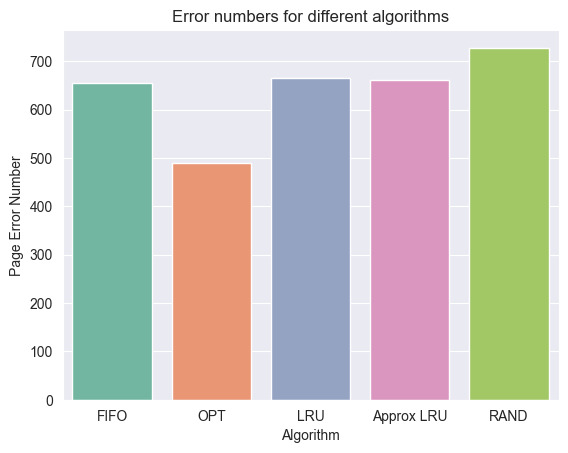

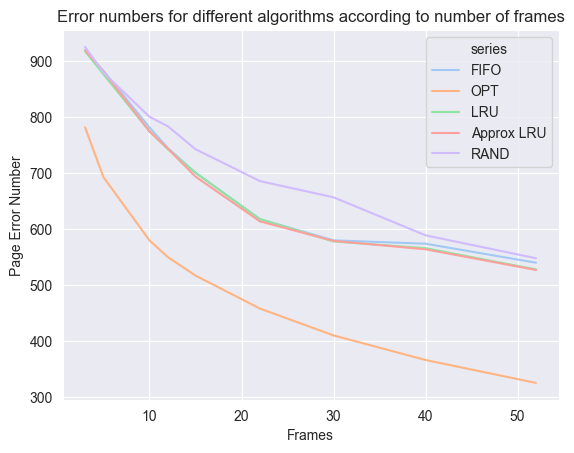

In [189]:
SIM_REF_SEQ = generate_reference_sequence(
    REFERENCE_SEQUENCE_LENGTH,
    LOCALITY_PROBABILITY,
    SPATIAL_LOCALITY_PROBABILITY,
    AVERAGE_REFERENCES_PER_SET,
    AVERAGE_SET_SIZE
)
print(len(set(SIM_REF_SEQ)))

output_fifo = fifo(SIM_REF_SEQ, PHYSICAL_FRAMES_COUNT)
output_opt = opt(SIM_REF_SEQ, PHYSICAL_FRAMES_COUNT)
output_lru = lru(SIM_REF_SEQ, PHYSICAL_FRAMES_COUNT)
output_approx_lru = approx_lru(SIM_REF_SEQ, PHYSICAL_FRAMES_COUNT)
output_rand = rand(SIM_REF_SEQ, PHYSICAL_FRAMES_COUNT)

df_data = {
    "Algorithm": ["FIFO", "OPT", "LRU", "Approx LRU", "RAND"],
    "Page Error Number": [output_fifo, output_opt, output_lru, output_approx_lru, output_rand],
}

df = pd.DataFrame(df_data)
print(df)

plt.title("Error numbers for different algorithms")
sns.barplot(x="Algorithm", y="Page Error Number", data=df, palette="Set2", hue="Algorithm")
plt.show()

y_fifo = []
y_opt = []
y_lru = []
y_approx_lru = []
y_rand = []

for frames_num in FRAMES_SIMULATION_SEQ:
    y_fifo.append(fifo(SIM_REF_SEQ, frames_num))
    y_opt.append(opt(SIM_REF_SEQ, frames_num))
    y_lru.append(lru(SIM_REF_SEQ, frames_num))
    y_approx_lru.append(approx_lru(SIM_REF_SEQ, frames_num))
    y_rand.append(rand(SIM_REF_SEQ, frames_num))

df = pd.DataFrame({
    "Frames": FRAMES_SIMULATION_SEQ * 5,
    "Page Error Number": y_fifo + y_opt + y_lru + y_approx_lru + y_rand,
    "series": ["FIFO"] * len(y_fifo) + ["OPT"] * len(y_opt) + ["LRU"] * len(y_lru) + ["Approx LRU"] * len(y_approx_lru) + ["RAND"] * len(y_rand),
})

plt.title("Error numbers for different algorithms according to number of frames")
sns.lineplot(x="Frames", y="Page Error Number", data=df, palette="pastel", hue="series")
plt.show()

